In [51]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.svm import SVC, SVR
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor

# Data handling and visualization
import matplotlib.pyplot as plt

# Data preparation and pipelines

# Train/validation splitting and model selection
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV,
)

# Common models
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor,
    GradientBoostingClassifier,
    GradientBoostingRegressor,
)

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

from catboost import CatBoostRegressor
from xgboost import XGBRegressor

ModuleNotFoundError: No module named 'catboost'

In [39]:
df=pd.read_csv('data/data.csv')
df.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [40]:
df.drop_duplicates(inplace=True)

In [22]:
df.info()

<class 'pandas.DataFrame'>
Index: 1005 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Cement              1005 non-null   float64
 1   Blast Furnace Slag  1005 non-null   float64
 2   Fly Ash             1005 non-null   float64
 3   Water               1005 non-null   float64
 4   Superplasticizer    1005 non-null   float64
 5   Coarse Aggregate    1005 non-null   float64
 6   Fine Aggregate      1005 non-null   float64
 7   Age                 1005 non-null   int64  
 8   Strength            1005 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 78.5 KB


In [41]:
df.describe()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
count,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000
mean,278.631343,72.043483,55.536318,182.075323,6.033234,974.376816,772.688259,45.856716,35.250378
std,104.344261,86.170807,64.207969,21.339334,5.919967,77.579667,80.340435,63.734692,16.284815
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,190.700000,0.000000,0.000000,166.600000,0.000000,932.000000,724.300000,7.000000,23.520000
50%,265.000000,20.000000,0.000000,185.700000,6.100000,968.000000,780.000000,28.000000,33.800000
75%,349.000000,142.500000,118.300000,192.900000,10.000000,1031.000000,822.200000,56.000000,44.870000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [23]:
# Number of zero values in each column
zero_counts = df.eq(0).sum()
print(zero_counts)

# Total number of zero values in the dataframe
print("Total zero values:", df.eq(0).sum().sum())

Cement                  0
Blast Furnace Slag    470
Fly Ash               541
Water                   0
Superplasticizer      378
Coarse Aggregate        0
Fine Aggregate          0
Age                     0
Strength                0
dtype: int64
Total zero values: 1389


In [42]:
x=df.drop('Strength',axis=1)
x
y=df['Strength']

In [16]:
from sklearn.feature_selection import mutual_info_regression
from sklearn.feature_selection import SelectKBest
fs=SelectKBest(score_func=mutual_info_regression,k=3)
fs.fit(x,y)
mi_scores = pd.Series(fs.scores_, index=x.columns)
mi_scores.sort_values(ascending=False, inplace=True)

In [17]:
mi_scores

Age                   0.358838
Water                 0.358808
Cement                0.303254
Coarse Aggregate      0.256475
Superplasticizer      0.213950
Fine Aggregate        0.209488
Blast Furnace Slag    0.179667
Fly Ash               0.119946
dtype: float64

In [30]:
from sklearn.feature_selection import VarianceThreshold
selector=VarianceThreshold(threshold=0)
X_new=selector.fit_transform(x)
X_new=pd.DataFrame(X_new,columns=selector.get_feature_names_out())
X_new

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28.0
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28.0
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270.0
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365.0
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360.0
...,...,...,...,...,...,...,...,...
1025,276.4,116.0,90.3,179.6,8.9,870.1,768.3,28.0
1026,322.2,0.0,115.6,196.0,10.4,817.9,813.4,28.0
1027,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28.0
1028,159.1,186.7,0.0,175.6,11.3,989.6,788.9,28.0


In [34]:
# Variance of each column in the feature DataFrame
column_variances = X_new.var()
print(column_variances)

Cement                10921.580220
Blast Furnace Slag     7444.124812
Fly Ash                4095.616541
Water                   456.002651
Superplasticizer         35.686781
Coarse Aggregate       6045.677357
Fine Aggregate         6428.187792
Age                    3990.437729
dtype: float64


In [35]:
correlations = df.corr(numeric_only=True)["Strength"].drop("Strength").sort_values(ascending=False)
print(correlations)

Cement                0.488283
Superplasticizer      0.344209
Age                   0.337367
Blast Furnace Slag    0.103374
Fly Ash              -0.080648
Coarse Aggregate     -0.144717
Fine Aggregate       -0.186448
Water                -0.269624
Name: Strength, dtype: float64


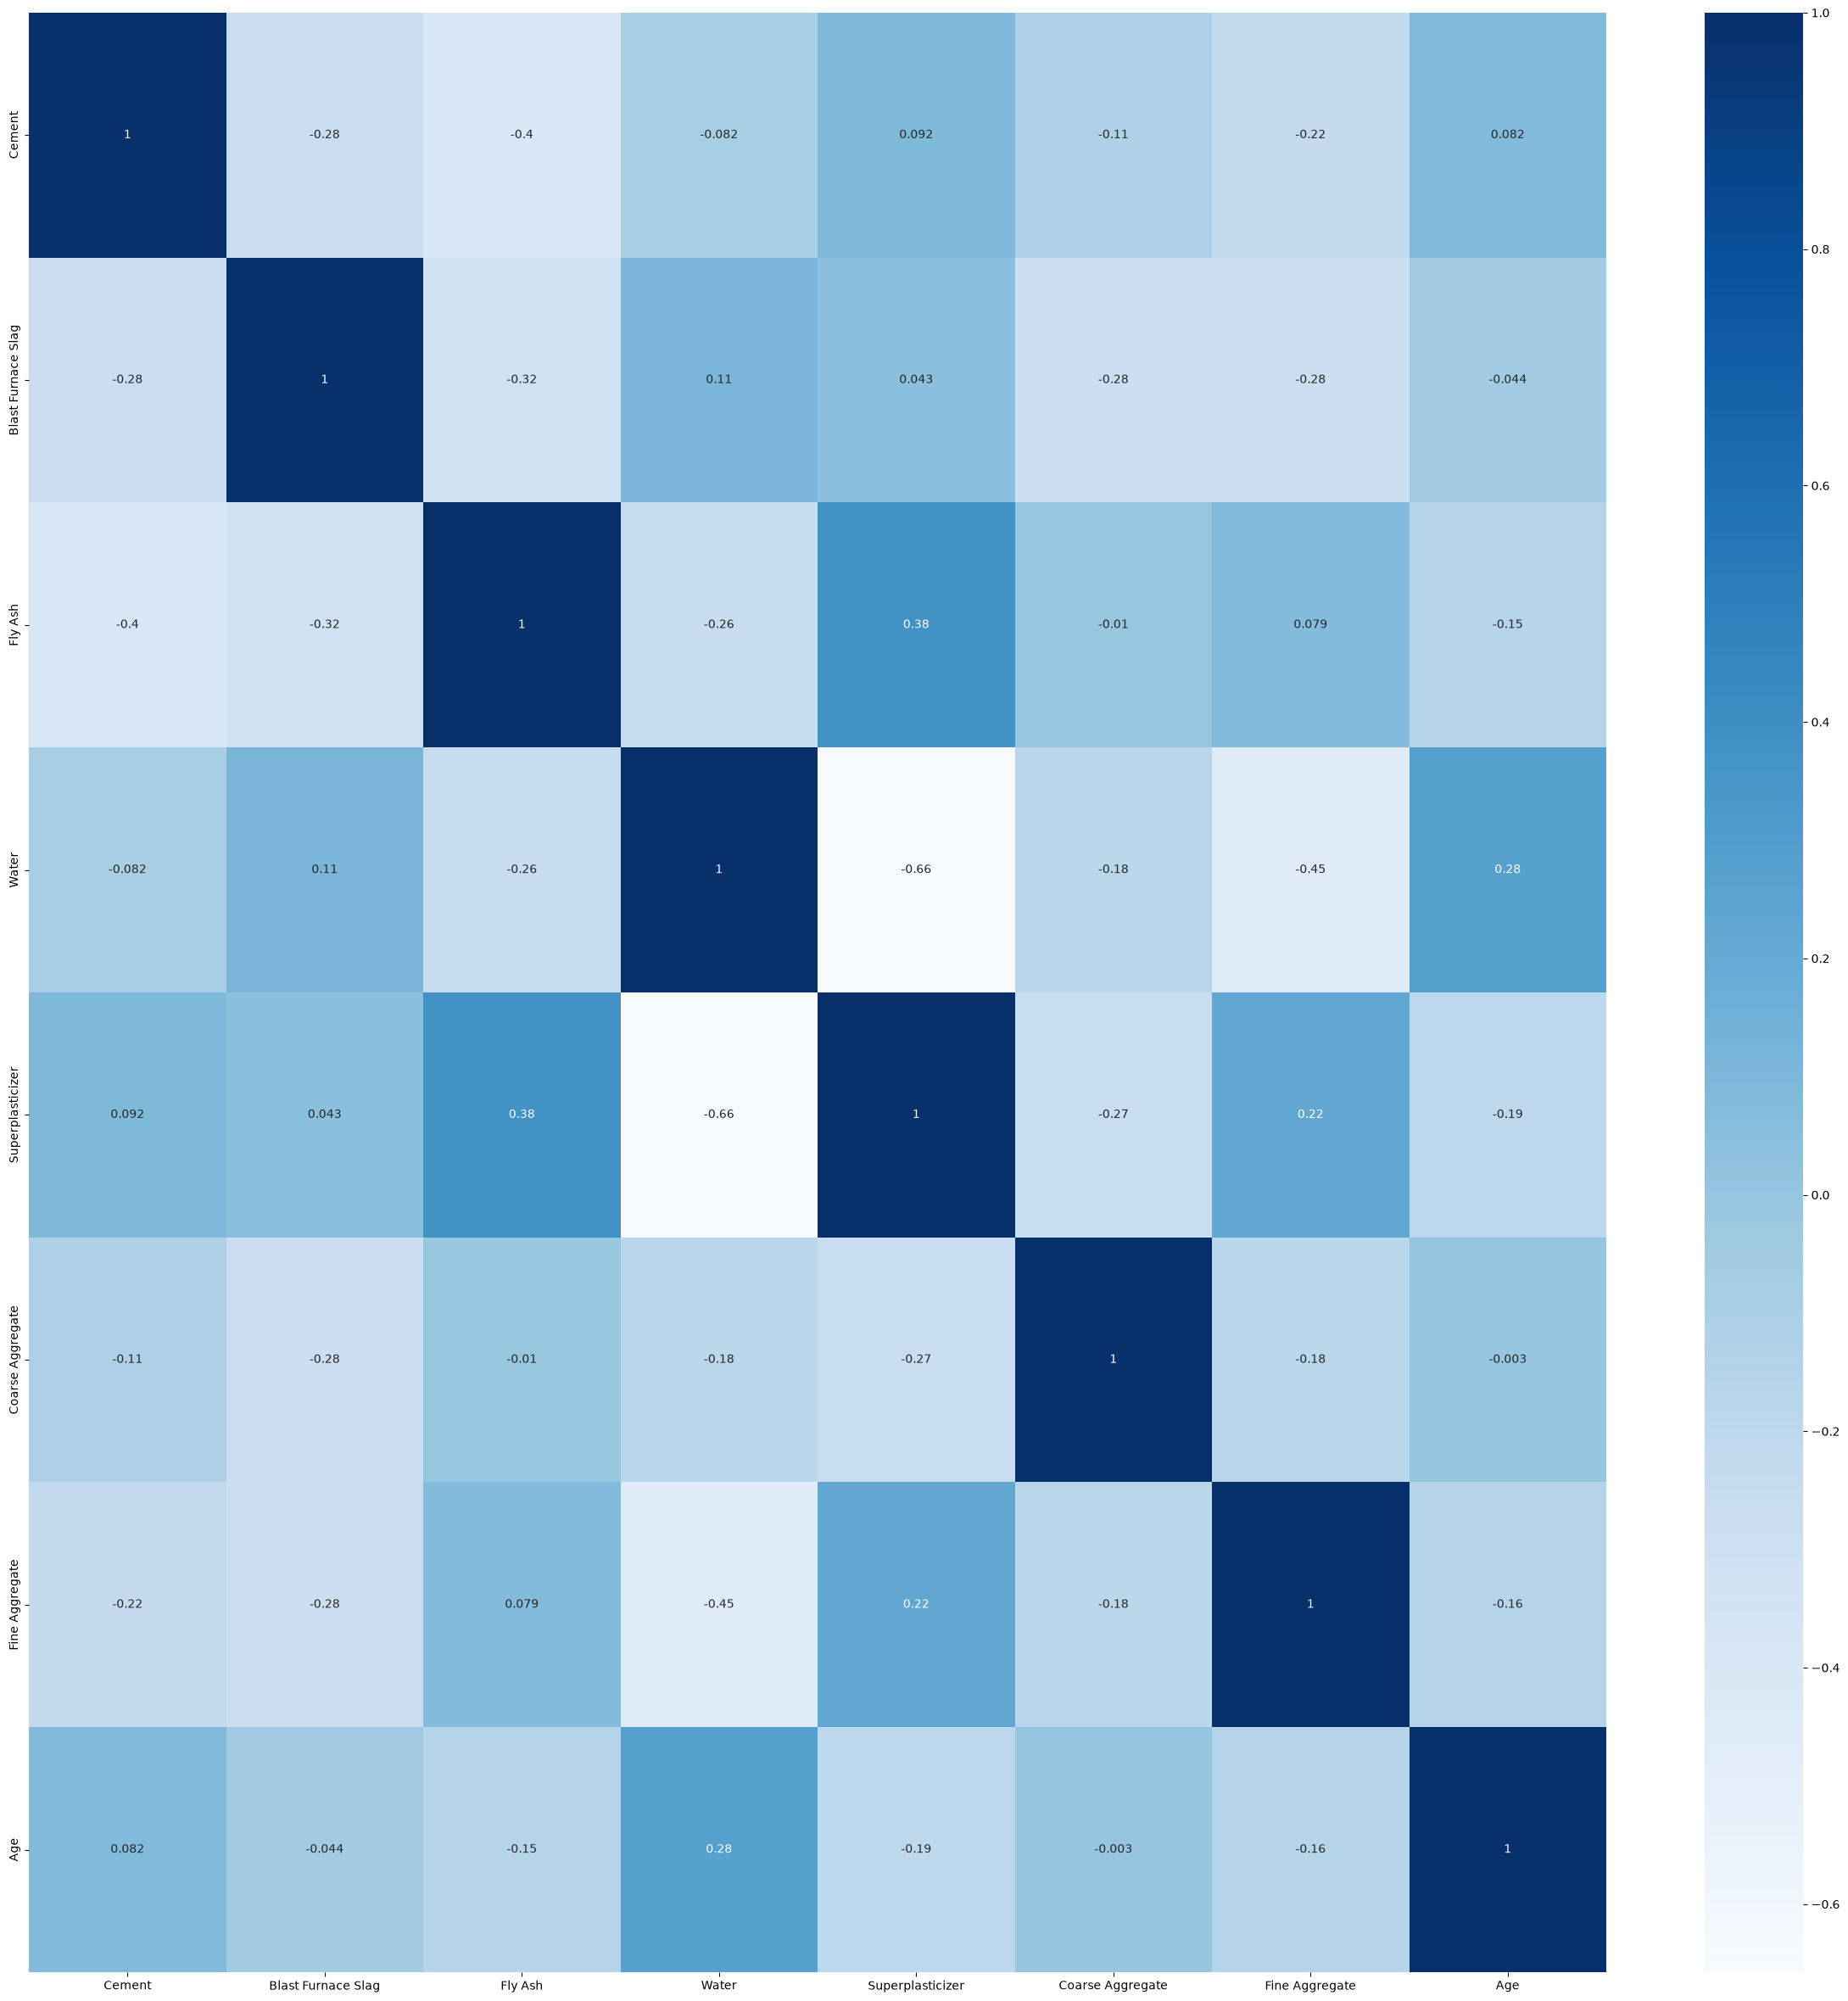

In [32]:
plt.figure(figsize=(30,30))
sns.heatmap(X_new.corr(),annot=True,cmap='Blues')
plt.show()

In [43]:
x=x.drop(['Fly Ash','Blast Furnace Slag'],axis=1)
x

,Cement,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age
0,540.0,162.0,2.5,1040.0,676.0,28
1,540.0,162.0,2.5,1055.0,676.0,28
2,332.5,228.0,0.0,932.0,594.0,270
3,332.5,228.0,0.0,932.0,594.0,365
4,198.6,192.0,0.0,978.4,825.5,360
...,...,...,...,...,...,...
1025,276.4,179.6,8.9,870.1,768.3,28
1026,322.2,196.0,10.4,817.9,813.4,28
1027,148.5,192.7,6.1,892.4,780.0,28
1028,159.1,175.6,11.3,989.6,788.9,28


In [ ]:
y=df['Strength']


### Model Training

In [56]:
X_train,y_train,X_test,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [48]:
def evealuate_model(true,predicted):

    mae=mean_absolute_error(true,predicted)
    mse=mean_squared_error(true,predicted)
    rmse=np.sqrt(mse)
    r2=r2_score(true,predicted)
    return mae,mse,rmse,r2


In [57]:
models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "K-Neighbors Regressor": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest Regressor": RandomForestRegressor(),
     
    
    
}
model_list = []
r2_list =[]

for i in range(len(list(models))):
    model = list(models.values())[i]
    model.fit(X_train, y_train) # Train model

    # Make predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    
    # Evaluate Train and Test dataset
    model_train_mae , model_train_rmse, model_train_r2 = evaluate_model(y_train, y_train_pred)

    model_test_mae , model_test_rmse, model_test_r2 = evaluate_model(y_test, y_test_pred)

    
    print(list(models.keys())[i])
    model_list.append(list(models.keys())[i])
    
    print('Model performance for Training set')
    print("- Root Mean Squared Error: {:.4f}".format(model_train_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_train_mae))
    print("- R2 Score: {:.4f}".format(model_train_r2))

    print('----------------------------------')
    
    print('Model performance for Test set')
    print("- Root Mean Squared Error: {:.4f}".format(model_test_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_test_mae))
    print("- R2 Score: {:.4f}".format(model_test_r2))
    r2_list.append(model_test_r2)
    
    print('='*35)
    print('\n')

ValueError: Found input variables with inconsistent numbers of samples: [804, 201]